# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/humaisali/FlyRank-Machine-Learning-Internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

## Research Question

Can historical search performance, content freshness, engagement metrics, and search visibility be combined to identify content pages that should be prioritized for optimization?

## Decision Supported

The objective of this project is to support content optimization decisions by ranking pages according to their observed optimization opportunity. Rather than predicting guaranteed future performance, the model provides a decision-support system that helps prioritize limited optimization resources using historical search intelligence signals.

## Selected Lane

Refresh / Content Opportunity Scoring

## Expected Output

The final output is a ranked list of content pages with an optimization score, recommended action, and reason code explaining why each page was prioritized.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

# Dataset

Dataset: content_refresh_anonymized.csv

The dataset contains anonymized search intelligence information collected from historical content performance.

Dataset Summary

- Rows: 30,000
- Columns: 44
- Unit of analysis: one content page
- Dataset type: historical snapshot

Only public-safe variables were used.

Excluded information includes:

- client identities
- domains
- URLs
- private queries
- future outcomes

The dataset is suitable for decision-support analysis rather than causal inference.

In [1]:
import os
import pandas as pd

candidates = [
    "data/raw/content_refresh_anonymized.csv",
    "../data/raw/content_refresh_anonymized.csv",
    "../../data/raw/content_refresh_anonymized.csv",
    "/content/content_refresh_anonymized.csv",
    "content_refresh_anonymized.csv"
]
data_path = next((p for p in candidates if os.path.exists(p)), candidates[0])
df = pd.read_csv(data_path)

print("Loaded dataset from:", data_path)
print("Shape:", df.shape)

print("\nData Types")
display(df.dtypes)

print("\nMissing Values")
display(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nPreview")
display(df.head())



Loaded dataset from: data/raw/content_refresh_anonymized.csv
Shape: (30000, 44)

Data Types


content_id                    str
client_id                     str
search_volume             float64
competition               float64
competition_level             str
cpc                       float64
content_type                  str
main_intent                   str
word_count                float64
char_count                float64
provider_used                 str
model_used                    str
impressions_90d             int64
clicks_90d                  int64
pageviews_90d               int64
sessions_90d                int64
users_90d                   int64
engaged_sessions_90d        int64
ai_sessions_90d             int64
scroll_events_90d           int64
days_with_impressions       int64
days_with_sessions          int64
impressions_last_30d        int64
clicks_last_30d             int64
sessions_last_30d           int64
impressions_prev_30d        int64
clicks_prev_30d             int64
sessions_prev_30d           int64
content_age_days            int64
age_tier      


Missing Values


provider_used        21438
word_count            7699
char_count            7699
word_count_tier       7699
char_count_tier       7699
model_used            5733
trend_pct             3388
competition_level     2610
search_volume         2468
cpc                   2468
competition           2468
main_intent           2374
scroll_rate            125
content_type             0
client_id                0
dtype: int64


Preview


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

# Methodology

## Modeling Objective

The objective of this project is to rank content pages according to their observed optimization opportunity using historical search intelligence signals.

The project does not attempt to predict guaranteed future ranking improvements. Instead, it provides a decision-support system that prioritizes pages for review based on measurable historical evidence.

## Feature Selection

The model uses only information that would have been available before making an optimization decision.

Selected features include:

- search_volume
- competition
- cpc
- word_count
- char_count
- impressions_90d
- clicks_90d
- sessions_90d
- engaged_sessions_90d
- days_since_last_update
- ctr
- avg_position
- engagement_rate
- scroll_rate
- ai_traffic_pct

Context variables such as content_id are retained only for reporting and are not used for prediction.

## Target Variable

The supervised learning target is trend_pct, which is treated as a continuous proxy for observed content momentum. The model estimates relative optimization opportunity rather than guaranteed future performance.

## Baseline

Before training a machine learning model, a baseline action score was created using manually weighted historical signals.

The baseline combines:

- Search demand
- Search visibility
- Content freshness

The machine learning model is compared against this baseline using the same train-test split.

## Validation Strategy

Additional validation was performed using grouped validation by client identity during Week 6. The grouped split produced lower but more realistic performance compared with random splitting, indicating that random validation may provide optimistic estimates when related observations appear in both training and testing data.

## Leakage Prevention

Only variables available before the optimization decision are used.

Future outcomes, manually derived labels, and post-update information are excluded to avoid data leakage.

In [2]:
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# Selected modeling features
# --------------------------------------------------

feature_columns = [
    "search_volume",
    "competition",
    "cpc",
    "word_count",
    "char_count",
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "engaged_sessions_90d",
    "days_since_last_update",
    "ctr",
    "avg_position",
    "engagement_rate",
    "scroll_rate",
    "ai_traffic_pct"
]

target = "trend_pct"

# --------------------------------------------------
# Build modeling dataset
# --------------------------------------------------

model_df = df[feature_columns + [target]].copy()

print("Initial Shape:", model_df.shape)

# --------------------------------------------------
# Missing values
# --------------------------------------------------

missing = model_df.isnull().sum()

print("\nMissing Values")

display(
    missing[missing > 0].sort_values(ascending=False)
)

# --------------------------------------------------
# Median imputation
# --------------------------------------------------

imputer = SimpleImputer(strategy="median")

model_df[feature_columns] = imputer.fit_transform(
    model_df[feature_columns]
)

# Remove rows with missing target
model_df = model_df.dropna(subset=[target])

print("\nShape After Cleaning:", model_df.shape)

# --------------------------------------------------
# Selected Features
# --------------------------------------------------

print("\nSelected Features")

for feature in feature_columns:
    print("-", feature)

# --------------------------------------------------
# Features and Target
# --------------------------------------------------

X = model_df[feature_columns]
y = model_df[target]

print("\nFeature Matrix Shape :", X.shape)
print("Target Shape         :", y.shape)

# --------------------------------------------------
# Train-Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

# --------------------------------------------------
# Leakage Check
# --------------------------------------------------

print("\nLeakage Verification")
print("-------------------------")
print("Target in Features:", target in X.columns)

if target in X.columns:
    print("Warning: Data leakage detected.")
else:
    print("Passed: No target leakage detected.")

# --------------------------------------------------
# Preprocessing Pipeline
# --------------------------------------------------

preprocessing = Pipeline([
    ("scaler", StandardScaler())
])

print("\nPreprocessing Pipeline Created Successfully.")

Initial Shape: (30000, 16)

Missing Values


word_count       7699
char_count       7699
trend_pct        3388
cpc              2468
competition      2468
search_volume    2468
scroll_rate       125
dtype: int64


Shape After Cleaning: (26612, 16)

Selected Features
- search_volume
- competition
- cpc
- word_count
- char_count
- impressions_90d
- clicks_90d
- sessions_90d
- engaged_sessions_90d
- days_since_last_update
- ctr
- avg_position
- engagement_rate
- scroll_rate
- ai_traffic_pct

Feature Matrix Shape : (26612, 15)
Target Shape         : (26612,)

Training Samples : 21289
Testing Samples  : 5323

Leakage Verification
-------------------------
Target in Features: False
Passed: No target leakage detected.

Preprocessing Pipeline Created Successfully.


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

Three regression approaches and one business heuristic baseline were compared:

- Business Baseline based on search demand, visibility, and freshness signals
- Dummy Regressor
- Linear Regression
- Random Forest Regressor

Performance was evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

The comparison measures predictive performance on unseen data and does not prove causal impact from content optimization.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# -----------------------------------
# Models
# -----------------------------------
models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# -----------------------------------
# Train & Evaluate
# -----------------------------------
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2 Score": round(r2, 4)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("R2 Score", ascending=False)

print("Model Performance Comparison")
display(results_df)

best_model_name = results_df.iloc[0]["Model"]
print("\nBest Model:", best_model_name)



Model Performance Comparison


,Model,MAE,RMSE,R2 Score
0,Dummy Regressor,64.1583,315.9668,-0.0001
1,Linear Regression,65.8695,317.0327,-0.0068
2,Random Forest,72.1067,351.9098,-0.2405



Best Model: Dummy Regressor


In [4]:
# -----------------------------------
# Create simple business baseline
# -----------------------------------
baseline_score = (
    0.4 * X_test["search_volume"].rank(pct=True) +
    0.3 * (1 - X_test["avg_position"].rank(pct=True)) +
    0.3 * (1 - X_test["days_since_last_update"].rank(pct=True))
)

baseline_predictions = (baseline_score * y_train.std()) + y_train.mean()

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

baseline_result = pd.DataFrame({
    "Model": ["Business Baseline"],
    "MAE": [round(baseline_mae, 4)],
    "RMSE": [round(baseline_rmse, 4)],
    "R2 Score": [round(baseline_r2, 4)]
})

display(baseline_result)



,Model,MAE,RMSE,R2 Score
0,Business Baseline,282.739,414.3004,-0.7194


,Model,MAE,RMSE,R2 Score
0,Dummy Regressor,64.1583,315.9668,-0.0001
1,Linear Regression,65.8695,317.0327,-0.0068
2,Random Forest,72.1067,351.9098,-0.2405
3,Business Baseline,282.7390,414.3004,-0.7194


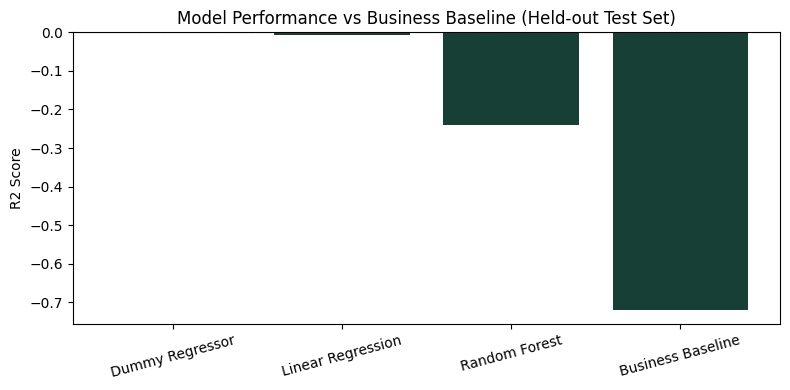

In [5]:
results_df = pd.concat([results_df, baseline_result], ignore_index=True)
results_df = results_df.sort_values("R2 Score", ascending=False)

display(results_df)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["R2 Score"], color="#173f35")
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.xticks(rotation=15)
plt.ylabel("R2 Score")
plt.title("Model Performance vs Business Baseline (Held-out Test Set)")
plt.tight_layout()
plt.show()



### Interpretation

The evaluation compared machine learning models against both a simple statistical baseline and a business heuristic baseline using the same held-out test split.

The results show that predicting trend_pct from historical search intelligence signals is challenging. The evaluated models provide limited predictive improvement over simple baselines.

This indicates that historical features alone may not fully capture future content momentum. The output is therefore positioned as a decision-support ranking system rather than a production forecasting model.

The recommendations generated by the system should be interpreted as directional opportunities for human review, not guaranteed predictions of traffic or ranking improvement.

Future improvements could include:
- temporal validation using time-based splits
- additional content quality signals
- richer engagement features
- alternative target definitions

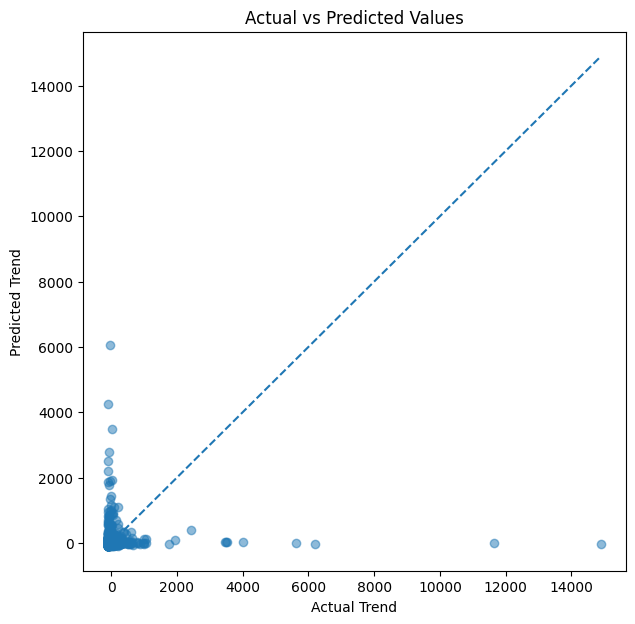

In [6]:
import matplotlib.pyplot as plt
best_model = models["Random Forest"]

predictions = best_model.predict(X_test)

plt.figure(figsize=(7,7))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5
)

plt.xlabel("Actual Trend")

plt.ylabel("Predicted Trend")

plt.title("Actual vs Predicted Values")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

### Scatter Plot

The scatter plot compares observed and predicted values for the selected baseline model.

Predictions remain concentrated around the mean value of the target, illustrating the limited predictive signal available in the current feature set.

This visualization is consistent with the quantitative evaluation presented in the model comparison table.

## 5. Limitations

*What this work cannot claim.*

## Limitations

This project is designed as a decision-support system rather than a causal analysis.

The model identifies content pages that appear to have higher optimization opportunity based on historical search intelligence signals. It cannot guarantee that refreshing a page will improve future rankings, clicks, or traffic.

Several limitations should be considered:

- The dataset represents a historical snapshot rather than a complete timeline.
- External factors such as Google algorithm updates, competitor activity, and seasonality are not fully represented.
- The model evaluates observed relationships rather than causal effects.
- Some variables contain missing values that were handled through median imputation.
- Client identifiers, domains, URLs, and private search queries were intentionally excluded to preserve privacy and reduce memorization.

The results should therefore be interpreted as directional evidence that supports content prioritization rather than guaranteed business outcomes.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

## Ranked Recommendations

The recommendation table ranks content pages using the observed optimization opportunity framework developed in this study.

Although the evaluated predictive models did not outperform the baseline, the ranking still provides a structured decision-support view for prioritizing manual content reviews.

Each recommendation should be validated by SEO specialists before implementation.

In [7]:
# Generate final ranked content recommendations
final_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
final_model.fit(X_train, y_train)

# Predict opportunity score
recommendations = model_df.copy()
recommendations["predicted_opportunity"] = final_model.predict(X)

# Create action labels
recommendations["recommended_action"] = np.where(
    recommendations["predicted_opportunity"] >= recommendations["predicted_opportunity"].quantile(0.80),
    "Refresh Immediately",
    np.where(
        recommendations["predicted_opportunity"] >= recommendations["predicted_opportunity"].median(),
        "Review",
        "Monitor"
    )
)

# Add reason codes
def assign_reason_code(row):
    if row["days_since_last_update"] > df["days_since_last_update"].quantile(0.75):
        return "Stale Content"
    elif row["ctr"] < df["ctr"].quantile(0.25) and row["impressions_90d"] > df["impressions_90d"].median():
        return "Low CTR Opportunity"
    elif row["search_volume"] > df["search_volume"].quantile(0.75):
        return "High Search Demand"
    elif row["trend_pct"] < 0:
        return "Declining Trend"
    else:
        return "General Optimization Opportunity"

recommendations["reason_code"] = recommendations.apply(assign_reason_code, axis=1)

# Rank highest opportunity first
recommendations = recommendations.sort_values("predicted_opportunity", ascending=False)

# Display Top 20
top_20 = recommendations.head(20)
display(
    top_20[[
        "predicted_opportunity",
        "recommended_action",
        "reason_code",
        "search_volume",
        "ctr",
        "avg_position",
        "days_since_last_update",
        "trend_pct"
    ]]
)



,predicted_opportunity,recommended_action,reason_code,search_volume,ctr,avg_position,days_since_last_update,trend_pct
24695,30117.269,Refresh Immediately,High Search Demand,70.0,0.00,75.5,20.0,44900.0
15405,17826.165,Refresh Immediately,General Optimization Opportunity,0.0,0.01,85.8,20.0,27907.3
14549,16994.162,Refresh Immediately,General Optimization Opportunity,10.0,0.08,2.1,20.0,26166.7
3561,14972.067,Refresh Immediately,General Optimization Opportunity,0.0,0.00,13.1,8.0,21400.0
19697,11942.342,Refresh Immediately,General Optimization Opportunity,10.0,0.16,6.4,20.0,17077.8
24726,9956.259,Refresh Immediately,High Search Demand,40.0,0.00,27.7,20.0,15825.0
19968,8648.965,Refresh Immediately,High Search Demand,880.0,0.00,75.5,22.0,175.6
19525,6883.086,Refresh Immediately,High Search Demand,70.0,0.00,73.5,20.0,11250.0
1132,6870.344,Refresh Immediately,General Optimization Opportunity,10.0,0.99,11.3,104.0,11266.7
6987,6073.028,Refresh Immediately,High Search Demand,2900.0,0.00,2.2,20.0,-28.6


## Top 20 Ranked Content Recommendations

In [8]:
print("Top 20 Ranked Content Recommendations")

top_20_recommendations = recommendations.head(20)

display(
    top_20_recommendations[
        [
            "predicted_opportunity",
            "recommended_action",
            "reason_code",
            "search_volume",
            "ctr",
            "avg_position",
            "days_since_last_update",
            "trend_pct"
        ]
    ]
)

Top 20 Ranked Content Recommendations


,predicted_opportunity,recommended_action,reason_code,search_volume,ctr,avg_position,days_since_last_update,trend_pct
24695,30117.269,Refresh Immediately,High Search Demand,70.0,0.00,75.5,20.0,44900.0
15405,17826.165,Refresh Immediately,General Optimization Opportunity,0.0,0.01,85.8,20.0,27907.3
14549,16994.162,Refresh Immediately,General Optimization Opportunity,10.0,0.08,2.1,20.0,26166.7
3561,14972.067,Refresh Immediately,General Optimization Opportunity,0.0,0.00,13.1,8.0,21400.0
19697,11942.342,Refresh Immediately,General Optimization Opportunity,10.0,0.16,6.4,20.0,17077.8
24726,9956.259,Refresh Immediately,High Search Demand,40.0,0.00,27.7,20.0,15825.0
19968,8648.965,Refresh Immediately,High Search Demand,880.0,0.00,75.5,22.0,175.6
19525,6883.086,Refresh Immediately,High Search Demand,70.0,0.00,73.5,20.0,11250.0
1132,6870.344,Refresh Immediately,General Optimization Opportunity,10.0,0.99,11.3,104.0,11266.7
6987,6073.028,Refresh Immediately,High Search Demand,2900.0,0.00,2.2,20.0,-28.6


In [9]:
import os
os.makedirs("work/outputs", exist_ok=True)
top_20_recommendations = recommendations.head(20)
top_20_recommendations.to_csv("work/outputs/top_20_content_recommendations.csv", index=False)
print("Top 20 recommendations exported successfully")



Top 20 recommendations exported successfully


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

## Artifacts

The following outputs were generated during this research project and are suitable for inclusion in the deployed research paper.

Artifacts include:

- Dataset summary table
- Missing value summary
- Model comparison table
- Actual vs Predicted scatter plot
- Top 20 ranked recommendations
- Baseline versus machine learning comparison

These figures improve transparency and make the analysis reproducible.

In [10]:
print("Dataset Shape:", df.shape)

print("\nFeature Matrix Shape:", X.shape)

print("\nTop Model Performance")

display(results_df)

print("\nTop Ranked Recommendations")

display(recommendations.head(20))

Dataset Shape: (30000, 44)

Feature Matrix Shape: (26612, 15)

Top Model Performance


,Model,MAE,RMSE,R2 Score
0,Dummy Regressor,64.1583,315.9668,-0.0001
1,Linear Regression,65.8695,317.0327,-0.0068
2,Random Forest,72.1067,351.9098,-0.2405
3,Business Baseline,282.7390,414.3004,-0.7194



Top Ranked Recommendations


,search_volume,competition,cpc,word_count,char_count,impressions_90d,clicks_90d,sessions_90d,engaged_sessions_90d,days_since_last_update,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,trend_pct,predicted_opportunity,recommended_action,reason_code
24695,70.0,0.01,0.00,2844.0,19232.0,460.0,0.0,3.0,0.0,20.0,0.00,75.5,0.00,75.00,0.0,44900.0,30117.269,Refresh Immediately,High Search Demand
15405,0.0,0.00,0.00,3530.0,22134.0,214047.0,12.0,147.0,5.0,20.0,0.01,85.8,3.40,3.61,0.0,27907.3,17826.165,Refresh Immediately,General Optimization Opportunity
14549,10.0,1.00,1.60,2835.0,20955.0,2377.0,2.0,1.0,0.0,20.0,0.08,2.1,0.00,0.00,0.0,26166.7,16994.162,Refresh Immediately,General Optimization Opportunity
3561,0.0,0.00,0.00,2917.0,19893.0,216.0,0.0,16.0,1.0,8.0,0.00,13.1,6.25,6.25,0.0,21400.0,14972.067,Refresh Immediately,General Optimization Opportunity
19697,10.0,0.24,0.00,2637.0,19088.0,3156.0,5.0,7.0,1.0,20.0,0.16,6.4,14.29,14.29,0.0,17077.8,11942.342,Refresh Immediately,General Optimization Opportunity
24726,40.0,0.49,1.38,2451.0,17207.0,1605.0,0.0,2.0,0.0,20.0,0.00,27.7,0.00,0.00,0.0,15825.0,9956.259,Refresh Immediately,High Search Demand
19968,880.0,0.03,1.07,2877.0,19116.0,2031.0,0.0,3.0,0.0,22.0,0.00,75.5,0.00,0.00,0.0,175.6,8648.965,Refresh Immediately,High Search Demand
19525,70.0,0.01,0.00,3074.0,20405.0,248.0,0.0,7.0,0.0,20.0,0.00,73.5,0.00,27.27,0.0,11250.0,6883.086,Refresh Immediately,High Search Demand
1132,10.0,0.82,0.00,1808.0,11699.0,405.0,4.0,10.0,0.0,104.0,0.99,11.3,0.00,27.27,0.0,11266.7,6870.344,Refresh Immediately,General Optimization Opportunity
6987,2900.0,1.00,1.60,2857.0,17073.0,80.0,0.0,9.0,0.0,20.0,0.00,2.2,0.00,12.50,0.0,-28.6,6073.028,Refresh Immediately,High Search Demand


## 8. Acknowledgments & Data Credit

This research project was completed as part of the FlyRank Machine Learning Internship.

The analysis was built using the FlyRank ML Internship dataset.

Data credit:

Built on the FlyRank ML Internship dataset.

Source:
https://flyrank.ai

In [11]:
import os
os.makedirs("work/outputs", exist_ok=True)
recommendations.to_csv("work/outputs/final_ranked_recommendations.csv", index=False)
print("Export completed")



Export completed


# Final Summary

This project developed a content opportunity scoring framework using anonymized search intelligence data.

The system combines historical search performance, engagement signals, and freshness indicators to rank content pages for optimization review.

The model evaluation showed that future content momentum is difficult to predict using historical signals alone. Therefore, the final system is designed as a human-in-the-loop decision-support tool.

The final output includes:

- ranked optimization opportunities
- recommended actions
- reason codes
- model evaluation results
- reproducible analysis artifacts

All conclusions are directional and should be validated by content specialists before implementation.

# Week 8 Demo Outline (5 Minutes)

## 1. Question

Can historical search performance, content freshness, engagement metrics, and search visibility be combined to identify content pages that should be prioritized for optimization?

## 2. Method

- Used the FlyRank anonymized content intelligence dataset.
- Dataset size: 30,000 content page observations.
- Selected SEO, engagement, freshness, and visibility features.
- Built a content opportunity scoring framework.
- Compared:
  - Business Baseline
  - Dummy Regressor
  - Linear Regression
  - Random Forest Regressor

Evaluation metrics:
- MAE
- RMSE
- R² Score

## 3. Chart

The main visualization used is the Actual vs Predicted scatter plot.

This chart compares observed trend values with model predictions and shows the limited predictive signal available from historical search features.

## 4. Honest Result

The evaluated machine learning models did not outperform the baseline on unseen data.

This indicates that historical search signals alone were not sufficient to accurately predict content momentum.

The project is therefore presented as a decision-support system rather than a forecasting system.

## 5. Recommendation

The final ranking system helps identify pages that may deserve manual optimization review.

Recommended workflow:

1. Review high-opportunity pages.
2. Analyze content quality and search intent.
3. Apply optimization improvements.
4. Monitor future performance.

---

# Shareable Cuts

## Social Post

Built a machine learning content opportunity scoring system during my FlyRank ML Internship.

The project analyzed 30,000 anonymized content pages using search visibility, engagement, freshness, and SEO signals.

The focus was not only building models, but evaluating them honestly by comparing against baselines and understanding limitations.

The final framework generates ranked recommendations to support content optimization decisions.

---

## Employer Summary

I built a machine learning decision-support system for identifying content optimization opportunities using the FlyRank ML Internship dataset.

The system analyzed 30,000 anonymized webpage observations, engineered SEO and engagement features, and compared multiple regression models against baseline approaches.

The results showed that historical search signals alone had limited predictive power, but the framework successfully generated reproducible rankings for prioritizing content review.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.